# AAPL order flow decomposition (hypothesis 2) - December 30, 2019

**Research question.** In [02_mid_price_prediction.ipynb](02_mid_price_prediction.ipynb) we saw
that the order flow imbalance (OFI) of the last second helps to predict the mid-price change over
the next 5 seconds, beyond the static state of the book (hypothesis 1). Here we ask the next
question of `TODO.md`:

**Hypothesis 2.** Does splitting the aggregated OFI into additions, cancellations, replacements
and executions improve the forecast compared with the aggregated OFI alone?

This notebook reuses the data and the pipeline of notebook 02, so that the two hypotheses are
compared on exactly the same footing. It only adds the decomposition and the tests that go with it.

## Contents
1. [Models and tests](#models)
2. [Data and order book replay](#replay)
3. [Decomposed OFI and 1-second grid](#grid)
4. [Split, estimation helpers and reproduction of H1](#helpers)
5. [Out-of-sample comparison](#oos)
6. [In-sample tests on the coefficients](#insample)
7. [Robustness: expanding windows](#expanding)
8. [Conclusion and limits](#conclusion)

<a id="models"></a>

## 1. Models and tests

Let $Y_t = (P_{mid}(t+5s) - P_{mid}(t)) / 0.01$ be the 5-second mid-price change in ticks.
Static features are the spread, the level-1 imbalance and the log of the level-1 depth, as in
notebook 02. Four flow groups are built from the message that caused each change of the best
quotes: `add` (A, F), `cancel` (X, D), `exec` (E, C) and `replace` (U).

- **M1**: static features only.
- **M2**: static features + total OFI over $(t-1s, t]$ (the model of H1).
- **M3**: static features + the four flow groups over $(t-1s, t]$.

Because the groups add up to the total OFI, M2 is M3 with the constraint that the four
coefficients are equal. So H2 is a test of nested models:

- **$H_0$**: the four coefficients are equal (the decomposition brings nothing) and M3 does not
  forecast better than M2.
- **$H_1$**: the coefficients differ and M3 forecasts better than M2 out of sample.

Tests used:
- in-sample Wald test of equal coefficients, with Newey-West (HAC) standard errors;
- out-of-sample Clark-West test, which is designed for nested models (the Diebold-Mariano test
  of notebook 02 is not, because the larger model has extra parameters that add noise under
  $H_0$);
- the same comparison on 5 expanding windows, to check that the result does not rely on one split.

We also fit each group alone and M3 without one group, as an exploration (it is not a
confirmatory test, see the limits).

<a id="replay"></a>

## 2. Data and order book replay

Same file as before: `data/default/AAPL_2019-12-30.parquet` (1,519,367 events). The replay,
the OFI and the 1-second grid are in [flow_study.py](flow_study.py), because notebook 04 applies
them to several days. The replay follows `replay_order_book` of notebook 02, written with two
small helpers instead of repeated blocks; it keeps regular hours and drops empty, locked or
crossed quotes, as before. Section 4 checks that we get exactly the results of notebook 02.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from analysis.data import load_market_data
from analysis.flow_study import (
    FLOW,
    GROUP_OF,
    GROUPS,
    STATIC,
    clark_west,
    event_ofi,
    fit_predict,
    one_second_grid,
    regular_hours_book,
    scores,
    split_day,
)
from common.enums import Ticker

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file() and (candidate / "common/schema.py").is_file()
)
DATA_PATH = ROOT / "data/default/AAPL_2019-12-30.parquet"
market = load_market_data(DATA_PATH, expected_ticker=Ticker.AAPL, expected_date=date(2019, 12, 30))
events = market.events.to_pandas()
print(f"{len(events):,} events for {market.ticker.value} on {market.session_date}")

1,519,367 events for AAPL on 2019-12-30


In [2]:
tob = regular_hours_book(events, market.session_date)
print(f"{len(tob):,} top-of-book states during regular hours")

1,484,261 top-of-book states during regular hours


<a id="grid"></a>

## 3. Decomposed OFI and 1-second grid

The event-level OFI is the one of Cont, Kukanov and Stoikov (2014), exactly as in notebook 02.
Since it is computed event by event, each contribution can be attributed to the message that
triggered it. We sum the contributions by group on every $(t-1s, t]$ window, with the same
alignment as before: static features use the last quote at or before $t$, the target looks at
$(t, t+5s]$, and there is no overlap between them.

In [3]:
# [review JS] Composition shows replace is only 2.4 % of events and ~1.15M shares.
# But in cell 16, its standardized coefficient is +0.21 ticks/sd because its std is
# small (155 shares). In raw terms (ticks/share), a replacement order has ~4x the
# estimated price impact of an addition. We should report both raw (ticks/share) and
# standardized (ticks/sd) coefficients to clarify why replacement flow exhibits high
# leverage and out-of-sample fragility.
# Event-level view of the decomposition: which messages move the best quotes, and by how much
flows = tob.assign(ofi=event_ofi(tob), group=tob["message_type"].map(GROUP_OF).fillna("other"))
assert (flows.loc[flows["group"] == "other", "ofi"] == 0).all()  # P, Q, S never move the quotes
moving = flows[flows["ofi"] != 0]
composition = pd.DataFrame(
    {
        "events with OFI != 0 (%)": 100 * moving["group"].value_counts(normalize=True),
        "sum of |OFI| (shares)": flows.groupby("group")["ofi"].apply(lambda s: s.abs().sum()),
    }
).loc[GROUPS]
print(composition.round(1).to_string())

         events with OFI != 0 (%)  sum of |OFI| (shares)
group                                                   
add                          49.5               20363425
cancel                       33.8               13543425
exec                         14.2                5028433
replace                       2.4                1152346


In [4]:
# Static features at t, flow groups summed over (t-1s, t], target over (t, t+5s]
data = one_second_grid(tob, market.session_date)
print(f"{len(data):,} one-second observations")
print(data[[*STATIC, "ofi", *FLOW, "target"]].describe().T[["mean", "std", "min", "max"]].round(2))

22,801 one-second observations
              mean      std       min       max
spread        0.03     0.01      0.01      0.09
obi_1         0.04     0.50     -1.00      1.00
log_depth     5.89     0.66      0.69     10.30
ofi          23.63  1075.40 -18411.00  30951.00
ofi_add      -4.22   785.43 -15991.00  18464.00
ofi_cancel   13.02   454.23  -6522.00  16210.00
ofi_exec     11.26   638.39 -38825.00  27985.00
ofi_replace   3.57   154.70  -5055.00   9600.00
target        0.06     4.69    -33.50     57.00


<a id="helpers"></a>

## 4. Split, estimation helpers and reproduction of H1

We keep the split of notebook 02: the first 70 % of the session for training, the last 30 % for
testing, and the last 5 training rows are purged because their target looks into the test period.
Features are standardized with training statistics only. The helpers of `flow_study.py`
(`split_day`, `fit_predict`, `scores`, `clark_west`) fit an OLS with Newey-West errors (5 lags, as
the target overlaps over 5 seconds) and evaluate it out of sample.

The **Clark-West** statistic compares a small model and a larger model that contains it. For the
squared errors $e_s^2$ and $e_b^2$ and the predictions $\hat y_s, \hat y_b$,
$f_t = e_s^2 - e_b^2 + (\hat y_s - \hat y_b)^2$ is regressed on a constant (HAC errors); a
significantly positive mean means the larger model forecasts better. The last term corrects the
bias caused by the extra parameters.

In [5]:
train, test = split_day(data)  # 70 % / 30 %, 5 purged rows
y_test, y_train_mean = test["target"].to_numpy(), train["target"].mean()
print(f"train: {len(train):,} rows ({train.index[0]:%H:%M} to {train.index[-1]:%H:%M})")
print(f"test:  {len(test):,} rows ({test.index[0]:%H:%M} to {test.index[-1]:%H:%M})")

# Reproduction check: notebook 02 reports MSE 11.1466 (M1), 11.1078 (M2) and beta_OFI = 0.2906
fit_m1, pred_m1 = fit_predict(STATIC, train, test)
fit_m2, pred_m2 = fit_predict([*STATIC, "ofi"], train, test)
mse_m1 = scores(y_test, pred_m1, y_train_mean)[0]
mse_m2 = scores(y_test, pred_m2, y_train_mean)[0]
print(f"MSE M1 = {mse_m1:.4f}, MSE M2 = {mse_m2:.4f}, beta_OFI = {fit_m2.params['ofi']:.4f}")
assert abs(mse_m1 - 11.1466) < 5e-4 and abs(mse_m2 - 11.1078) < 5e-4
assert abs(fit_m2.params["ofi"] - 0.2906) < 5e-4
print("The pipeline reproduces the results of notebook 02.")

train: 15,955 rows (09:35 to 14:00)
test:  6,841 rows (14:01 to 15:55)
MSE M1 = 11.1466, MSE M2 = 11.1078, beta_OFI = 0.2906
The pipeline reproduces the results of notebook 02.


<a id="oos"></a>

## 5. Out-of-sample comparison

We compare the benchmarks (a zero forecast and the training mean), M1, M2, M3, each group alone
with the static features, and M3 without one group.

In [6]:
specs = {
    "zero forecast": None,
    "training mean": None,
    "M1 static": STATIC,
    "M2 static + total OFI": [*STATIC, "ofi"],
    "M3 static + 4 groups": [*STATIC, *FLOW],
}
for group in GROUPS:
    specs[f"static + {group} only"] = [*STATIC, f"ofi_{group}"]
for group in GROUPS:
    specs[f"M3 without {group}"] = [*STATIC, *[col for col in FLOW if col != f"ofi_{group}"]]

predictions = {}
for name, columns in specs.items():
    if name == "zero forecast":
        predictions[name] = np.zeros(len(test))
    elif name == "training mean":
        predictions[name] = np.full(len(test), y_train_mean)
    else:
        predictions[name] = fit_predict(columns, train, test)[1]

table = pd.DataFrame(
    [(name, *scores(y_test, pred, y_train_mean)) for name, pred in predictions.items()],
    columns=["model", "MSE", "MAE", "R2 oos"],
).set_index("model")
print(table.round(4).to_string())

                           MSE     MAE  R2 oos
model                                         
zero forecast          11.1605  2.4963  0.0029
training mean          11.1925  2.5080  0.0000
M1 static              11.1466  2.4973  0.0041
M2 static + total OFI  11.1078  2.4943  0.0076
M3 static + 4 groups   11.2155  2.5016 -0.0021
static + add only      11.0921  2.4921  0.0090
static + cancel only   11.1399  2.4964  0.0047
static + exec only     11.1362  2.4963  0.0050
static + replace only  11.2877  2.5079 -0.0085
M3 without add         11.2766  2.5069 -0.0075
M3 without cancel      11.2137  2.5009 -0.0019
M3 without exec        11.2150  2.5014 -0.0020
M3 without replace     11.1051  2.4940  0.0078


In [7]:
pairs = [
    ("zero forecast", "M1 static"),
    ("M1 static", "M2 static + total OFI"),
    ("M2 static + total OFI", "M3 static + 4 groups"),
]
rows = []
for small, big in pairs:
    gain, t_stat, p_value = clark_west(y_test, predictions[small], predictions[big])
    rows.append((f"{small} -> {big}", gain, t_stat, p_value))
cw = pd.DataFrame(rows, columns=["comparison", "mean adj. gain", "t-stat", "p-value"])
print(cw.set_index("comparison").round(4).to_string())

                                               mean adj. gain  t-stat  p-value
comparison                                                                    
zero forecast -> M1 static                             0.0377  1.9789   0.0239
M1 static -> M2 static + total OFI                     0.0854  3.3485   0.0004
M2 static + total OFI -> M3 static + 4 groups         -0.0123 -0.4380   0.6693


**Reading.** The Clark-West test confirms H1 (M1 to M2: the gain is small but significantly
positive). It does not support H2: M3 has a *higher* MSE than M2 (11.22 against 11.11) and a
negative out-of-sample $R^2$, and the Clark-West test does not reject equality (p = 0.67). Among
the exploratory variants, "static + add only" has the lowest MSE, but we chose it after looking at
the results, so we do not claim it as a finding.

Note that this Clark-West test on M1 to M2 is more favourable to H1 than the Diebold-Mariano
test of notebook 02 (p = 0.07), which is conservative when the models are nested.

<a id="insample"></a>

## 6. In-sample tests on the coefficients

The aggregated model is the restriction that the four raw coefficients are equal, so a Wald test
on a model estimated with the raw (unstandardized) flows tests H2 directly. We run it on the
training sample and on the whole day, with 5 and 10 HAC lags.

In [8]:
def wald_tests(sample, lags):
    exog = sm.add_constant(sample[[*STATIC, *FLOW]])
    fit = sm.OLS(sample["target"], exog).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    names = list(exog.columns)
    equal = np.zeros((len(FLOW) - 1, len(names)))
    for i in range(len(FLOW) - 1):
        equal[i, names.index(FLOW[i])], equal[i, names.index(FLOW[i + 1])] = 1, -1
    none = np.zeros((len(FLOW), len(names)))
    for i, column in enumerate(FLOW):
        none[i, names.index(column)] = 1
    test_equal = fit.wald_test(equal, use_f=False, scalar=True)
    test_none = fit.wald_test(none, use_f=False, scalar=True)
    return test_equal, test_none


rows = []
for label, sample in [("train", train), ("whole day", data)]:
    for lags in (5, 10):
        equal, none = wald_tests(sample, lags)
        rows.append((label, lags, float(equal.statistic), float(equal.pvalue), float(none.pvalue)))
wald = pd.DataFrame(
    rows, columns=["sample", "HAC lags", "chi2(3) equal coefs", "p equal", "p all flow = 0"]
)
print(wald.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

   sample  HAC lags  chi2(3) equal coefs   p equal  p all flow = 0
    train         5                30.19  1.26e-06       8.316e-11
    train        10                29.45 1.802e-06       2.346e-10
whole day         5                8.698   0.03359       4.932e-09
whole day        10                8.359   0.03914       1.139e-08


             coef (ticks per sd)  t-stat  p-value
ofi_add                   0.2808  4.0846   0.0000
ofi_cancel                0.0915  1.3124   0.1894
ofi_exec                  0.0394  0.7249   0.4685
ofi_replace               0.2109  3.3492   0.0008
M2, total OFI: 0.2906 (t = 5.36)


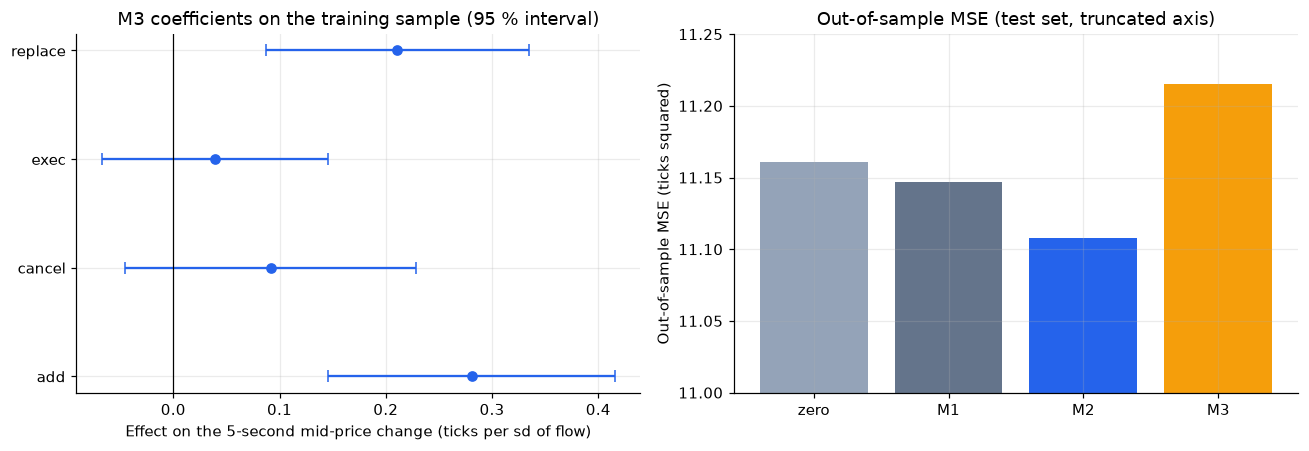

In [9]:
# [review JS] Bias-variance tradeoff & Ridge shrinkage on M3:
# In-sample, the Wald test rejects equality (p < 0.001), but out-of-sample M3 degrades
# (MSE 11.22 vs 11.11). This is a classic bias-variance tradeoff under multicollinearity:
# M2 has slight specification bias but low estimation variance, whereas M3's 4 free
# flow parameters suffer high estimation variance on test data.
# To test if decomposition has predictive value without unconstrained OLS variance,
# we should try an L2 Ridge shrinkage on M3 (shrinking the 4 coefficients toward each
# other / toward M2) to see if regularized M3 beats M2.
# Also, note the contrast between raw impact (ticks/share) and standardized impact
# (ticks/sd) for replace vs add.
fit_m3, _ = fit_predict([*STATIC, *FLOW], train, test)
coefficients = pd.DataFrame(
    {"coef (ticks per sd)": fit_m3.params, "t-stat": fit_m3.tvalues, "p-value": fit_m3.pvalues}
).loc[FLOW]
conf = fit_m3.conf_int().loc[FLOW]
print(coefficients.round(4).to_string())
print(f"M2, total OFI: {fit_m2.params['ofi']:.4f} (t = {fit_m2.tvalues['ofi']:.2f})")

coef = coefficients["coef (ticks per sd)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].errorbar(
    coef,
    range(len(FLOW)),
    xerr=[coef - conf[0], conf[1] - coef],
    fmt="o",
    color="#2563eb",
    capsize=4,
)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_yticks(range(len(FLOW)), GROUPS)
axes[0].set_xlabel("Effect on the 5-second mid-price change (ticks per sd of flow)")
axes[0].set_title("M3 coefficients on the training sample (95 % interval)")

to_plot = ["zero forecast", "M1 static", "M2 static + total OFI", "M3 static + 4 groups"]
axes[1].bar(
    ["zero", "M1", "M2", "M3"],
    [table.loc[name, "MSE"] for name in to_plot],
    color=["#94a3b8", "#64748b", "#2563eb", "#f59e0b"],
)
axes[1].set_ylim(11.0, 11.25)
axes[1].set_ylabel("Out-of-sample MSE (ticks squared)")
axes[1].set_title("Out-of-sample MSE (test set, truncated axis)")
plt.tight_layout()
plt.show()

**Reading.** In sample the four components do not have the same coefficient: the equality test is
rejected on the training sample (p < 0.001) and, less strongly, on the whole day (p = 0.03 to
0.04). Additions (+0.28 tick per sd, t = 4.1) and replacements (+0.21, t = 3.3) carry the signal;
cancellations (+0.09) and executions (+0.04) are not significant. The gap between the training
sample and the whole day suggests that the coefficients are not stable during the session, which
is consistent with the absence of an out-of-sample gain.

The weak role of executions is surprising at first, since they are the "aggressive" flow. Here
they only appear when they change the best quotes, they are a small share of the events that
move the OFI (about 14 %), and the aggressor side is not observed directly.

<a id="expanding"></a>

## 7. Robustness: expanding windows

A single split on one afternoon can be lucky or unlucky. We cut the session into 6 consecutive
blocks and, for each block $k = 1..5$, train on all earlier blocks (with the 5-row purge) and test
on block $k$. Predictions are then pooled and tested with Clark-West.

In [10]:
blocks = np.array_split(np.arange(len(data)), 6)
folds = {key: [] for key in ("zero", "M1", "M2", "M3", "y")}
rows = []
for k in range(1, 6):
    fold_train, fold_test = data.iloc[: blocks[k][0] - 5], data.iloc[blocks[k]]
    y_fold = fold_test["target"].to_numpy()
    fold_pred = {
        "zero": np.zeros(len(fold_test)),
        "M1": fit_predict(STATIC, fold_train, fold_test)[1],
        "M2": fit_predict([*STATIC, "ofi"], fold_train, fold_test)[1],
        "M3": fit_predict([*STATIC, *FLOW], fold_train, fold_test)[1],
    }
    for key, pred in fold_pred.items():
        folds[key].append(pred)
    folds["y"].append(y_fold)
    label = f"{fold_test.index[0]:%H:%M}-{fold_test.index[-1]:%H:%M}"
    rows.append((label, *[np.mean((y_fold - fold_pred[key]) ** 2) for key in fold_pred]))
print(pd.DataFrame(rows, columns=["test block", "zero", "M1", "M2", "M3"]).round(3).to_string())

pooled = {key: np.concatenate(value) for key, value in folds.items()}
pooled_mse = {key: np.mean((pooled["y"] - pooled[key]) ** 2) for key in ("zero", "M1", "M2", "M3")}
print("pooled MSE:", {key: round(float(value), 4) for key, value in pooled_mse.items()})
for small, big in [("M1", "M2"), ("M2", "M3")]:
    gain, t_stat, p_value = clark_west(pooled["y"], pooled[small], pooled[big])
    print(f"pooled Clark-West {small} -> {big}:", end=" ")
    print(f"gain = {gain:.4f}, t = {t_stat:.2f}, p = {p_value:.3f}")

    test block    zero      M1      M2      M3
0  10:38-11:41  21.529  21.781  21.777  21.793
1  11:41-12:45  20.240  20.307  20.244  20.289
2  12:45-13:48  12.306  12.288  12.270  12.244
3  13:48-14:51  10.789  10.838  10.780  10.960
4  14:51-15:55  11.477  11.418  11.403  11.393
pooled MSE: {'zero': 15.2683, 'M1': 15.3266, 'M2': 15.2946, 'M3': 15.336}
pooled Clark-West M1 -> M2: gain = 0.1043, t = 5.49, p = 0.000
pooled Clark-West M2 -> M3: gain = 0.0176, t = 1.30, p = 0.097


**Reading.** M2 is better than M1 on all 5 blocks and the pooled Clark-West test confirms H1.
M3 is better than M2 on only 2 of the 5 blocks and its pooled MSE is higher; the pooled
Clark-West test is borderline (p = 0.10) once the extra parameters are accounted for. The first
blocks are trained on about one hour only, which explains why even M1 and M2 are not better than
the zero forecast on the pooled sample: the gains over the naive forecast are fragile.

<a id="conclusion"></a>

## 8. Conclusion and limits

### Conclusion for hypothesis 2

- **In sample**, the decomposition matters: the four flow components do not share the same
  coefficient (Wald test), and the signal comes mostly from additions and replacements.
- **Out of sample**, it does not help: M3 is not better than M2 on the main split (Clark-West
  p = 0.67) and is better on only 2 of 5 expanding windows.
- So on this data we **cannot conclude that H2 holds**. The data are compatible with the
  decomposition having some value, but too noisy for us to detect a gain from four coefficients
  instead of one.

### Elements used

Data: AAPL, Nasdaq TotalView-ITCH 5.0, December 30, 2019, regular hours 09:35 to 15:55. Features
over the last second, target over the next 5 seconds, same alignment, split, purge and scaling as
notebook 02 (checked by the reproduction assertions). Tests: Wald (in sample), Clark-West (out of
sample, nested models), expanding windows.

### Limits

- **One stock, one day.** These results use AAPL on December 30, 2019 only. Notebook 04 repeats
  the test on a second day (July 30, 2019) and reaches the same conclusion for H2.
- **Few independent observations.** The test period has 6,841 one-second points, but the 5-second
  price changes of two neighbouring seconds share 4 seconds, so the points are far from
  independent. The test can therefore only detect large gains, and the gains we look for are
  tiny (H1 itself reduces the forecast error by 0.35 % only).
- **Best prices only.** The OFI only looks at the best bid and ask. Orders added or cancelled
  deeper in the book are not counted.
- **Replacements.** A `U` message cancels an order and adds a new one at the same time. We keep
  it as a separate group instead of splitting it in two; this is a choice.
- **Hidden trades.** Trades against hidden orders (`P` messages) do not change the visible book,
  so they are not in the OFI.
- **Extra models.** The models with one group only, or with one group removed, were added after
  the main results. With 8 extra models, some differences can come from chance. Only the M2 to
  M3 comparison was planned in advance.
- **Statistical choices.** Standard errors allow for the overlap of the 5-second changes (5 lags;
  10 lags give similar results). The p-values of the Clark-West test are approximate.
- **No trading strategy.** The gains are measured as forecast errors, not as profits, and
  trading costs are ignored.

### Next steps
- Repeat the test on more days (notebook 04 does it for one more day).
- Try a version of M3 that shrinks the four coefficients towards each other (ridge regression),
  which suits groups of flow that move together.